# University of Tehran
## Department of Electrical and Computer Engineering
### Engineering Probability & Statistics , Fall 2026
## Computer Assignment 2: Discrete & Continuous Random Variables

**Instructor:** Dr. Haghi  
**Designer:** Amirali Dehghani | **Supervisor:** Babak Hosseini Mohtasham  
**Deadline:** December 7, 2026 (۱۷ آذر ۱۴۰۵)  

---
### Student Identification:
* **Full Name: Mir Amirreza Seyyed Nasiri** 
* **Student ID: 810104424** 

---
### Instructions & Guidelines:
1. Complete all `# TODO` blocks and conceptual response markdown cells. Do not modify function signatures or return types.
2. **Grading & Structure:**
   * **Parts 1 through 4 (100 Points Total):** Core mandatory sections (25 points each).
   * **Part 5 (20 Bonus Points):** Non-Uniform Random Variate Generation is an optional bonus section.
3. **Library Usage:**
   * In **Section 1.1**, implement PMFs (`binomial_pmf`, `geometric_pmf`, `negative_binomial_pmf`) from first principles using standard arithmetic and combination formulas (`math.comb` is allowed). High-level distribution functions (such as `scipy.stats.binom.pmf`) are prohibited in this subsection to ensure solid conceptual mastery of discrete distributions.
   * In **Sections 1.2 through 4**, standard scientific libraries (`numpy`, `scipy.stats`, `matplotlib`) are fully authorized and recommended for sampling, computing theoretical benchmarks, and visualization.
   * In **Bonus Section 5**, random sampling must be performed solely via `np.random.uniform`.
4. Keep `np.random.seed(95)` for reproducibility.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import math

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
np.random.seed(95)
print("Libraries imported successfully.")

Libraries imported successfully.


---
## Part 1: Dinoco 400 Speedway & Discrete Random Variables (25 Points)

### Context:
In the Dinoco 400, Lightning McQueen (#95) competes against The King (#43) and Chick Hicks (#86). By foregoing a tire change to hold track position, McQueen's stint involves stochastic overtaking, tire degradation, and thermal telemetry warnings.

### 1.1. Manual PMF Implementations
Implement the following PMFs from first principles without calling distribution libraries:
1. `binomial_pmf(n, k, p)`:
   $$P(K = k) = \binom{n}{k} p^k (1 - p)^{n - k}, \quad k \in \{0, 1, \dots, n\}$$
2. `geometric_pmf(k, p)`:
   $$P(L = k) = (1 - p)^{k - 1} p, \quad k \ge 1$$
3. `negative_binomial_pmf(m, r, p)`:
   $$P(M = m) = \binom{m - 1}{r - 1} p^r (1 - p)^{m - r}, \quad m \ge r$$

In [ ]:
def binomial_pmf(n, k, p):
    """
    Compute Binomial PMF manually.
    P(K = k) = comb(n, k) * (p**k) * ((1-p)**(n-k))
    """
    probabily = math.comb(n, k) * math.pow(p, k) * math.pow(1 - p, n - k)
    return probabily

def geometric_pmf(k, p):
    """
    Compute Geometric PMF manually (trial of first success).
    P(L = k) = (1 - p)**(k - 1) * p
    """
    probabilty = math.pow(1 - p, k - 1) * p 
    return probabilty

def negative_binomial_pmf(m, r, p):
    """
    Compute Negative Binomial PMF manually (trial of r-th success).
    P(M = m) = comb(m - 1, r - 1) * (p**r) * ((1 - p)**(m - r))
    """
    probabilty = math.comb(m - 1, r - 1) * math.pow(p, r) * math.pow(1 - p, m - r)
    return probabilty

### 1.2. Monte Carlo Simulation ($N = 100,000$)

> **Self-Study & Exploration:**
> * **Monte Carlo Simulation:** Research how repeatedly drawing pseudo-random realizations estimates theoretical expectations and probabilities through the Law of Large Numbers (LLN):
>   $$\lim_{N \to \infty} \frac{1}{N} \sum_{i=1}^N \mathbb{I}_{A_i} = \mathbb{P}(A)$$
> * **Mean Squared Error (MSE):** Look up MSE for quantifying discrepancy between empirical relative frequencies and analytical PMF probabilities:
>   $$\mathrm{MSE} = \frac{1}{|\mathcal{K}|} \sum_{k \in \mathcal{K}} (\hat{p}_k - p_k)^2$$

Simulate $100,000$ independent trials for each scenario:
1. **Binomial:** $n = 20, p = 0.35$ (successful overtakes in 20 laps).
2. **Geometric:** $p_f = 0.04$ (lap of first tire puncture).
3. **Negative Binomial:** $r = 3, p_w = 0.15$ (lap of 3rd thermal sensor warning).

Plot empirical histograms against theoretical PMFs and report the Mean Squared Error (MSE) for each distribution.

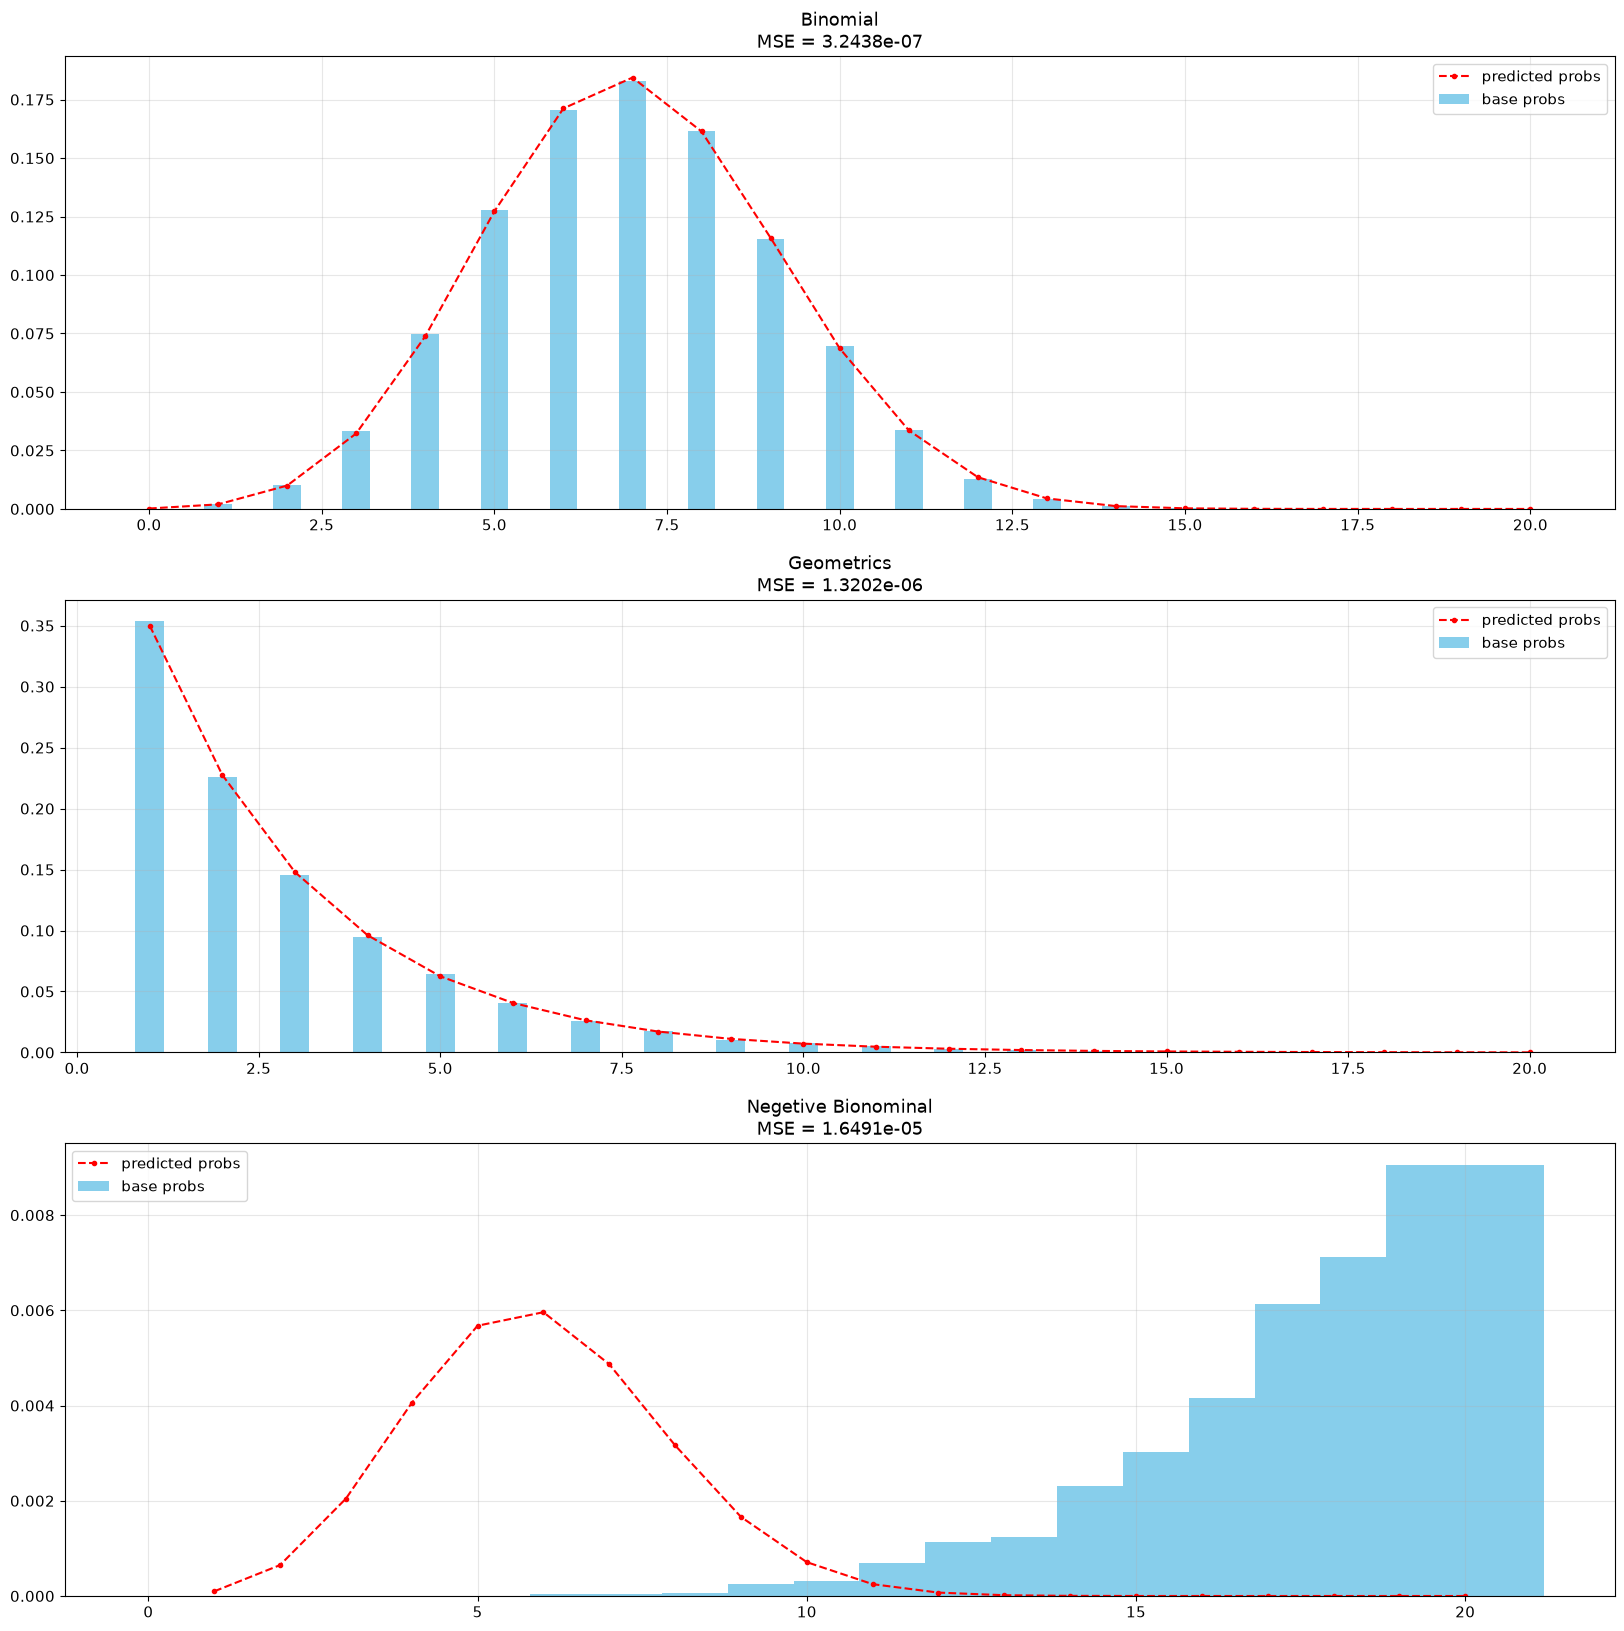

In [53]:
# TODO: Run Monte Carlo simulations (N = 100,000) for the three discrete distributions
figure, axes = plt.subplots(3, 1,figsize=(20, 20))

N_SAMPLES = 100_000
np.random.seed(95)


# bionominal 
succes_bionominal_rate: float = 0.35
succec_count = 20

x_range = np.arange(0, succec_count + 1)

sample_bionominal = np.random.binomial(size=N_SAMPLES, n=succec_count, p=succes_bionominal_rate)
base_probabilities_bionominal = np.array([np.mean(sample_bionominal == k) for k in x_range])
predicted_bionominal_samples = np.array([binomial_pmf(succec_count, k, succes_bionominal_rate) for k in x_range])

mse_bionominal = np.mean((predicted_bionominal_samples - base_probabilities_bionominal) ** 2)

# Plotting bionominal 
axes[0].bar(x_range, base_probabilities_bionominal, width=0.4, label='base probs', color='skyblue')
axes[0].plot(x_range, predicted_bionominal_samples, 'r--', label='predicted probs', marker='o', markersize=3)
axes[0].set_title(f"Binomial\nMSE = {mse_bionominal:.4e}")
axes[0].legend()


# geometrics
x_range_geom = np.arange(1, succec_count + 1)
sample_geometric = np.random.geometric(size=N_SAMPLES, p=succes_bionominal_rate)
base_probabilities_geometrics = np.array([np.mean(sample_geometric == k) for k in x_range_geom])
predicted_geometrics_samples = np.array([geometric_pmf(k, succes_bionominal_rate) for k in x_range_geom])
mse_geometrics = np.mean((predicted_geometrics_samples - base_probabilities_geometrics) ** 2)

axes[1].bar(x_range_geom, base_probabilities_geometrics, width=0.4, label='base probs', color='skyblue')
axes[1].plot(x_range_geom, predicted_geometrics_samples, 'r--', label='predicted probs', marker='o', markersize=3)
axes[1].set_title(f"Geometrics\nMSE = {mse_geometrics:.4e}")
axes[1].legend()

# negetive bionominal 
x_range_nbionominal = np.arange(1, succec_count + 1)
sample_negetive_bionominal = np.random.negative_binomial(n=succec_count, p=succes_bionominal_rate, size=N_SAMPLES)
base_probabilities_negetive_bionominal = np.array([np.mean(sample_negetive_bionominal == k) for k in x_range_nbionominal])
predicted_negetive_bionominal_samples = np.array([negative_binomial_pmf(p=succes_bionominal_rate, 
    m=succec_count, r=k) for k in x_range_nbionominal])
mse_negetive_bionominal = np.mean((base_probabilities_negetive_bionominal - predicted_negetive_bionominal_samples) ** 2)

# Plotting the negetive bionominal 
axes[2].bar(x_range_nbionominal, base_probabilities_negetive_bionominal, width=2.4, label='base probs', color='skyblue')
axes[2].plot(x_range_nbionominal, predicted_negetive_bionominal_samples, 'r--', label='predicted probs', marker='o', markersize=3)
axes[2].set_title(f"Negetive Bionominal\nMSE = {mse_negetive_bionominal:.4e}")
axes[2].legend()


### 1.3. Tire Wear vs. Memoryless Property
In physical systems, tires undergo progressive abrasive wear. Model lap-dependent failure probability as:
$$p_f(d) = \min(p_0 + \gamma d, 1.0)$$
where $p_0 = 0.01$ and $\gamma = 0.0015$.

1. Implement `simulate_tire_hazard(n_samples=50_000, p0=0.01, gamma=0.0015, max_laps=50)` to record failure laps across $N = 50,000$ tires.
2. For each lap $d \in \{1, 2, \dots, 50\}$, compute the empirical hazard rate:
   $$\hat{h}(d) = \frac{\text{Failures at lap } d}{\text{Tires surviving to start of lap } d}$$
3. Plot $\hat{h}(d)$ alongside the constant hazard rate of the Geometric distribution ($h = 0.04$).

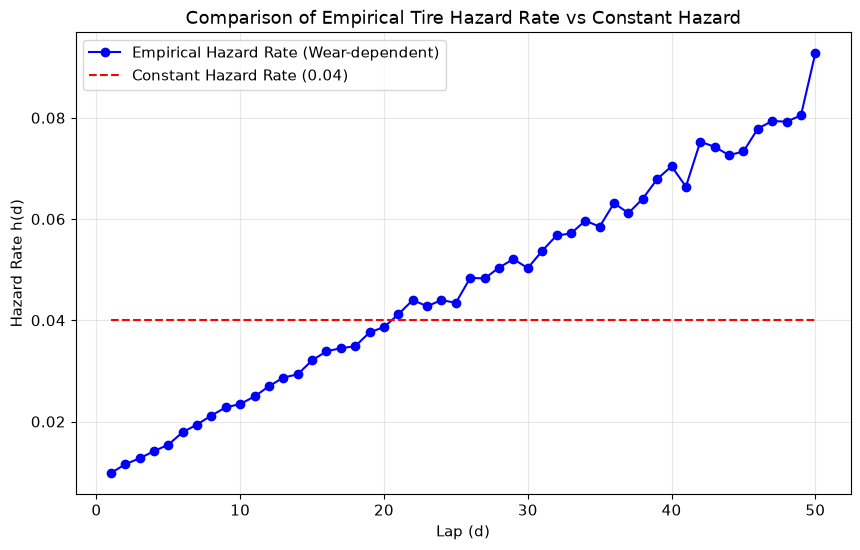

In [57]:
def simulate_tire_hazard(n_samples=50_000, p0=0.01, gamma=0.0015, max_laps=50, rng=None):
    """
    Simulate tire lifetimes under physical wear where failure probability grows with lap d:
    p_f(d) = min(p0 + gamma * d, 1.0)
    
    Returns:
        laps_range: np.ndarray from 1 to max_laps
        empirical_hazard: np.ndarray of empirical hazard rate at each lap
    """
    if rng is None:
        rng = np.random.default_rng()
    tire_status = np.zeros(n_samples, dtype=bool)
    failure_per_laps = np.zeros(max_laps)
    surviviors_at_start = np.zeros(max_laps)

    laps_range = np.arange(1, max_laps + 1)

    for d in range(max_laps):
        survivios = ~tire_status
        surviviors_at_start[d] = sum(survivios)

        prob_in_d = min(p0 + gamma * d, 1.0)
        random_prob = rng.random(n_samples)
        new_failures = survivios & (random_prob < prob_in_d)

        failure_per_laps[d] = np.sum(new_failures)
        tire_status = tire_status | new_failures
    emperical_hazard = failure_per_laps / surviviors_at_start
    return (
        laps_range, emperical_hazard
    )
    # TODO: Implement tire wear simulation and empirical hazard rate calculation
    pass

# TODO: Run simulation and plot empirical hazard rate vs constant geometric hazard rate (0.04)
laps, empirical_hazard = simulate_tire_hazard()
constant_hazard = np.full(50, 0.04)

plt.figure(figsize=(10, 6))
plt.plot(laps, empirical_hazard, 'bo-', label='Empirical Hazard Rate (Wear-dependent)')
plt.plot(laps, constant_hazard, 'r--', label='Constant Hazard Rate (0.04)')
plt.xlabel('Lap (d)')
plt.ylabel('Hazard Rate h(d)')
plt.title('Comparison of Empirical Tire Hazard Rate vs Constant Hazard')
plt.legend()
plt.grid(True)
plt.show()

### Conceptual Response 1:
* How closely do the empirical frequencies align with the theoretical PMFs? What explains the magnitude of the MSE?
* Contrast the constant hazard rate of the Geometric distribution with the wear-out hazard rate. Why is the memoryless property invalid for mechanical components subject to wear?

*(Write your response here)*

---
## Part 2: Casa Della Tires, Poisson Process & Memoryless Property (25 Points)

### 2.1. Binomial to Poisson Convergence
For $\lambda = 4.0$, compute the Binomial PMF across $k \in \{0, 1, \dots, 12\}$ with $p = \lambda / n$ for $n \in \{8, 25, 100, 1000\}$.
1. Plot the Binomial PMFs alongside the limiting $\mathrm{Poisson}(\lambda = 4.0)$ PMF.
2. Plot the maximum absolute error $\max_k |P_{\mathrm{Binomial}}(k) - P_{\mathrm{Poisson}}(k)|$ against $n$ on a log-log scale.

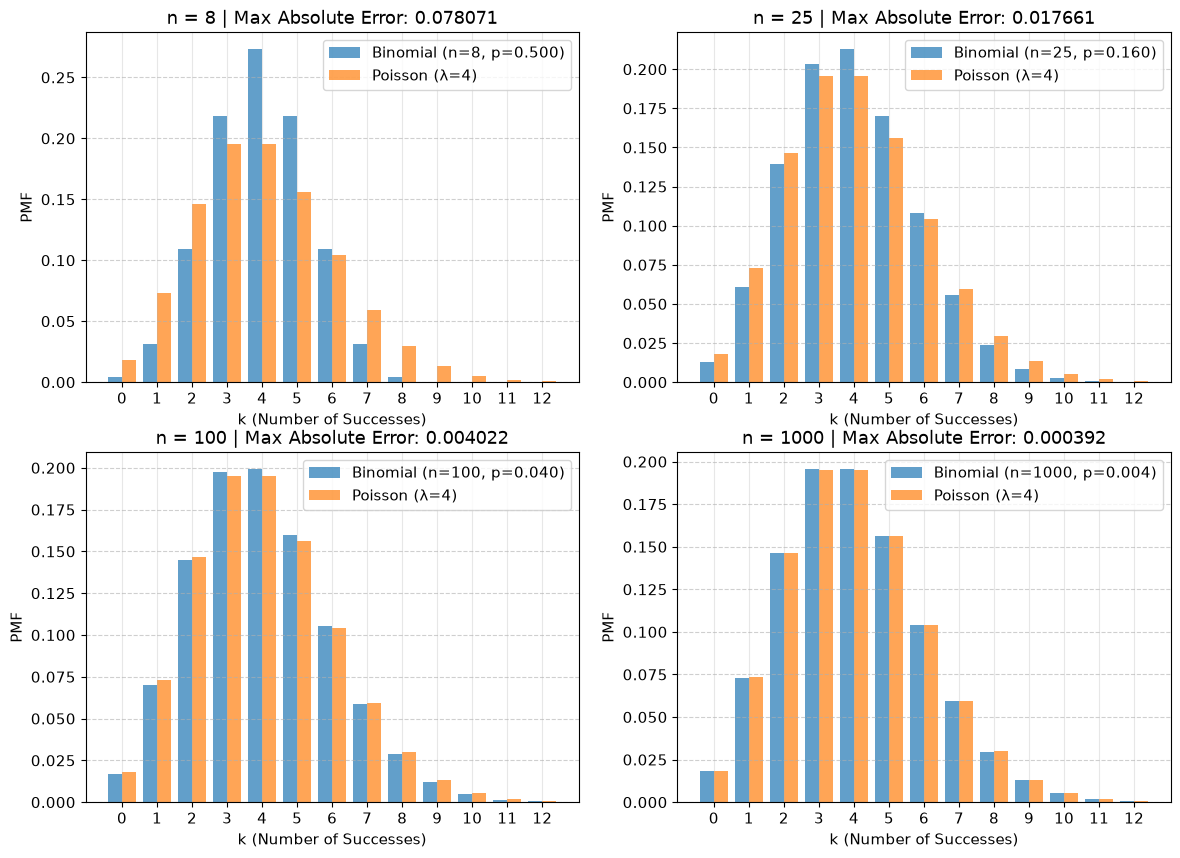

In [62]:
# TODO: Implement and plot Binomial-to-Poisson convergence and error decay
lam = 4.0
n_values = [8, 25, 100, 1000]
k_vals = np.arange(0, 13)

# Simulations
possion_pmf = stats.poisson.pmf(k_vals, lam)

plt.figure(figsize=(14, 10))

for i, n in enumerate(n_values):
    prob = lam / n
    bionominal_pmf = stats.binom.pmf(k_vals, n, prob)

    max_error = np.max(np.abs(possion_pmf - bionominal_pmf))

    plt.subplot(2, 2, i+1)
    plt.bar(k_vals - 0.2, bionominal_pmf, width=0.4, label=f'Binomial (n={n}, p={prob:.3f})', alpha=0.7)
    plt.bar(k_vals + 0.2, possion_pmf, width=0.4, label='Poisson (λ=4)', alpha=0.7)
    
    plt.title(f'n = {n} | Max Absolute Error: {max_error:.6f}')
    plt.xlabel('k (Number of Successes)')
    plt.ylabel('PMF')
    plt.xticks(k_vals)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.6)

### 2.2. Poisson Arrival Process Simulation
Customers arrive at Casa Della Tires with Poisson rate $\lambda = 2.5$ cars/hour.
1. Implement `simulate_poisson_day(lam=2.5, t_max=10.0)` by generating exponential inter-arrival times:
   $$\Delta t_i \sim \mathrm{Exponential}(\lambda)$$
2. Display an event plot of arrival timestamps for a single 10-hour day.
3. Simulate $5,000$ days, count arrivals in each 1-hour interval, and plot the empirical distribution against theoretical $\mathrm{Poisson}(\lambda = 2.5)$.

<>:52: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:52: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\Amirreza\AppData\Local\Temp\ipykernel_32832\3500962497.py:52: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  axes[1].plot(k_vals, theoretical_pmf, 'ro-', linewidth=2, markersize=6, label=f'Theoretical Poisson($\lambda={lam}$)')


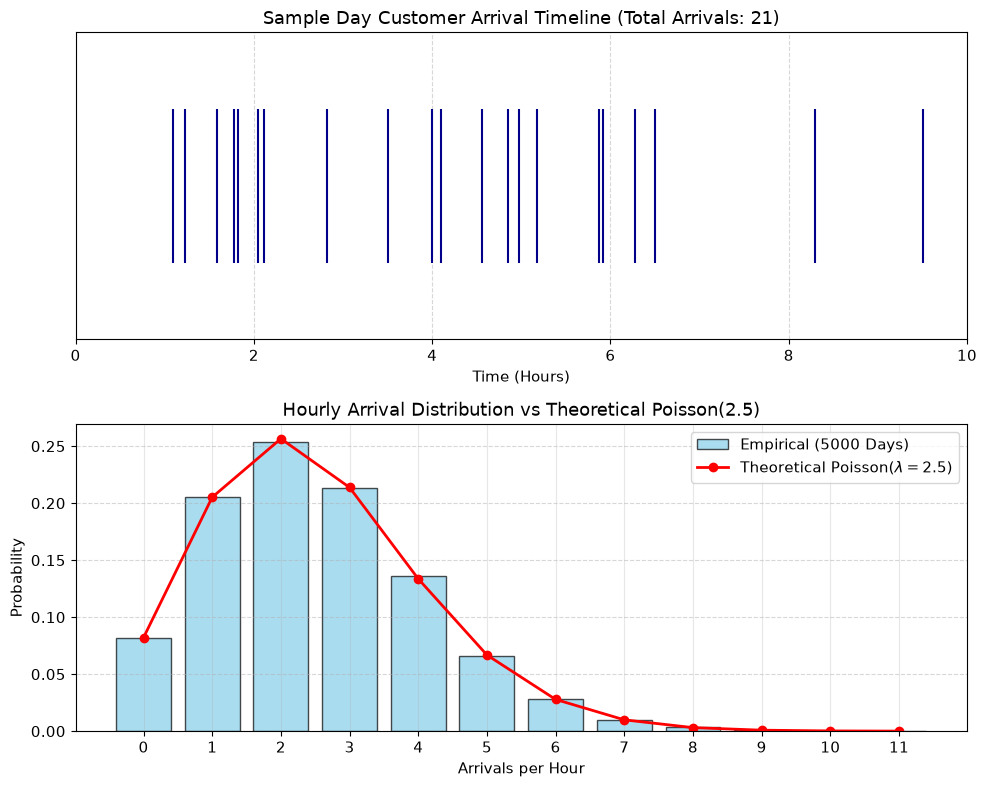

In [71]:
from scipy.stats import poisson

def simulate_poisson_day(lam, t_max):
    """
    Simulates customer arrival times in a single day using exponential inter-arrival times.
    """
    arrival_times = []
    current_time = 0.0
    while True:
        inter_arrival = np.random.exponential(scale=1.0 / lam)
        current_time += inter_arrival
        if current_time > t_max:
            break
        arrival_times.append(current_time)
    return np.array(arrival_times)

# Parameters
lam = 2.5
t_max = 10.0
n_days = 5000

# 1. Timeline plot for a sample day
sample_day_arrivals = simulate_poisson_day(lam, t_max)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Subplot 1: Timeline
axes[0].eventplot(sample_day_arrivals, orientation='horizontal', lineoffsets=0, linelengths=0.5, color='darkblue')
axes[0].set_xlim(0, t_max)
axes[0].set_ylim(-0.5, 0.5)
axes[0].set_yticks([])
axes[0].set_xlabel("Time (Hours)")
axes[0].set_title(f"Sample Day Customer Arrival Timeline (Total Arrivals: {len(sample_day_arrivals)})")
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# 2. Simulation over 5000 days and hourly histogram extraction
hourly_counts = []
for _ in range(n_days):
    day_arrivals = simulate_poisson_day(lam, t_max)
    counts, _ = np.histogram(day_arrivals, bins=np.arange(0, int(t_max) + 1))
    hourly_counts.extend(counts)

hourly_counts = np.array(hourly_counts)

# Subplot 2: Histogram vs Theoretical Poisson(2.5)
max_k = np.max(hourly_counts)
bins = np.arange(-0.5, max_k + 1.5, 1)
axes[1].hist(hourly_counts, bins=bins, density=True, rwidth=0.8, color='skyblue', edgecolor='black', alpha=0.7, label='Empirical (5000 Days)')

k_vals = np.arange(0, max_k + 1)
theoretical_pmf = poisson.pmf(k_vals, mu=lam)
axes[1].plot(k_vals, theoretical_pmf, 'ro-', linewidth=2, markersize=6, label=f'Theoretical Poisson($\lambda={lam}$)')

axes[1].set_xlabel("Arrivals per Hour")
axes[1].set_ylabel("Probability")
axes[1].set_title("Hourly Arrival Distribution vs Theoretical Poisson(2.5)")
axes[1].set_xticks(k_vals)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 2.3. Memoryless Property of Exponential Waiting Times
1. Generate $100,000$ samples of $T \sim \mathrm{Exponential}(\lambda=2.5)$ using inverse transform sampling:
   $$T = -\frac{\ln(1 - U)}{\lambda}, \quad U \sim \mathcal{U}(0, 1)$$
2. Filter for realizations where $T > s = 0.4$ hours ($24$ minutes) and compute residual waiting time $Y = T - s$.
3. Plot the empirical density of $Y$ against the unconditional distribution of $T$ and the theoretical curve $f_T(t) = 2.5 e^{-2.5 t}$.

<>:22: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:29: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:22: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:29: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\Amirreza\AppData\Local\Temp\ipykernel_32832\2399166563.py:22: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  label="Empirical Distribution of $T' = (T - s \mid T > s)$"
C:\Users\Amirreza\AppData\Local\Temp\ipykernel_32832\2399166563.py:29: SyntaxWarning: "\l" is an invalid

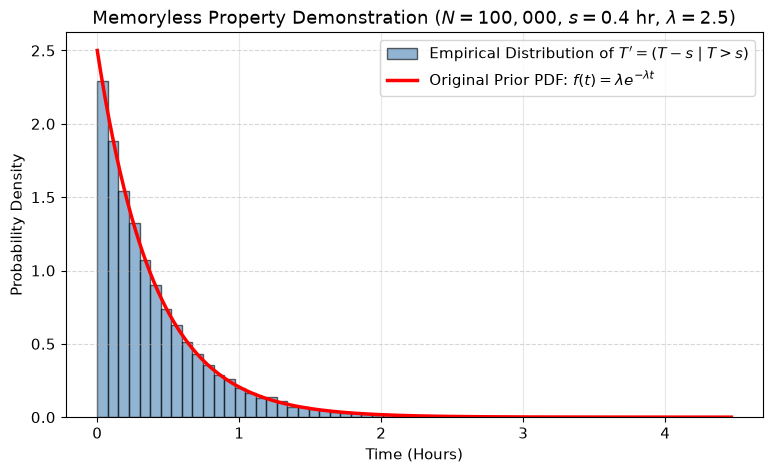

Mean of original samples (T): 0.4014 (Theoretical: 0.4000)
Mean of memoryless shifted samples (T'): 0.4021 (Theoretical: 0.4000)


In [73]:
# TODO: Simulate the memoryless property of the Exponential distribution

lam = 2.5
s = 0.4 
N = 100_000

rng = np.random.default_rng(seed=42)
T = rng.exponential(scale=1.0 / lam, size=N)
T_conditioned = T[T > s]

T_prime = T_conditioned - s

plt.figure(figsize=(9, 5))

count, bins, _ = plt.hist(
    T_prime, 
    bins=60, 
    density=True, 
    alpha=0.6, 
    color='steelblue', 
    edgecolor='black', 
    label="Empirical Distribution of $T' = (T - s \mid T > s)$"
)

t_vals = np.linspace(0, np.max(T_prime), 500)
pdf_theoretical = lam * np.exp(-lam * t_vals)
plt.plot(t_vals, pdf_theoretical, 'r-', linewidth=2.5, label=r"Original Prior PDF: $f(t) = \lambda e^{-\lambda t}$")

plt.title(f"Memoryless Property Demonstration ($N={N:,}$, $s={s}$ hr, $\lambda={lam}$)")
plt.xlabel("Time (Hours)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print(f"Mean of original samples (T): {np.mean(T):.4f} (Theoretical: {1/lam:.4f})")
print(f"Mean of memoryless shifted samples (T'): {np.mean(T_prime):.4f} (Theoretical: {1/lam:.4f})")


### Conceptual Response 2:
* Guido asserts: *"If no customer has arrived in the last 20 minutes, a customer is bound to arrive any moment."* Is this statement mathematically valid for a Poisson process? Explain in terms of the Gambler's Fallacy and the memoryless property.

*(Write your response here)*

---
## Part 3: Dirt Track Lap Times & Continuous Transformations (25 Points)

### 3.1. Gaussian Lap Times & Empirical Rule
Lap times at Willy's Butte are modeled as independent Gaussian random variables:
* Lightning McQueen: $T_M \sim \mathcal{N}(53.0, 1.5^2)$ seconds.
* Doc Hudson: $T_H \sim \mathcal{N}(50.2, 0.8^2)$ seconds.

1. Simulate $100,000$ laps for each driver.
2. Verify the 68-95-99.7 empirical rule on McQueen's lap times over $[\mu \pm k\sigma]$ for $k \in \{1, 2, 3\}$.
3. Compute the empirical probability that Doc Hudson finishes ahead ($D = T_M - T_H > 0$).
4. Plot both lap time distributions alongside the 51.0-second track record marker.

In [8]:
# TODO: Simulate lap times, verify empirical rule, and compute head-to-head win probability
mu_M, sig_M = 53.0, 1.5
mu_H, sig_H = 50.2, 0.8
N_LAPS = 100_000


### 3.2. Quadratic Transformation of a Gaussian Variable

> **Self-Study & Exploration:**
> * Research the **Gamma Distribution** and its connection to squared standard Gaussians (the **Chi-Squared Distribution** $\chi_1^2$).
> * Observe how squaring a zero-mean Gaussian variable $\Theta \sim \mathcal{N}(0, \sigma_\theta^2)$ generates a Gamma random variable $Y = c\Theta^2 \sim \mathrm{Gamma}(\alpha = 1/2, \beta = \frac{1}{2c\sigma_\theta^2})$, where $\alpha$ is the shape parameter and $\beta$ is the rate parameter.

Steering angle deviation is modeled as $\Theta \sim \mathcal{N}(0, \sigma_\theta^2)$ with $\sigma_\theta = 0.5$ rad. The kinetic energy dissipated in lateral wheel slip is $Y = c \Theta^2$ with $c = 2.0 \, \mathrm{J/rad^2}$.
1. Generate $100,000$ realizations of $\Theta$ and compute $Y = c \Theta^2$.
2. Verify that the sample mean and variance match theoretical moments: $\mathbb{E}[Y] = c\sigma_\theta^2 = 0.5$ and $\mathrm{Var}(Y) = 2c^2\sigma_\theta^4 = 0.5$.
3. Plot the empirical density of $Y$ against the derived analytical PDF:
   $$f_Y(y) = \frac{1}{\sigma_\theta \sqrt{2\pi c}} y^{-1/2} e^{-\frac{y}{2 c \sigma_\theta^2}}, \quad y > 0$$

In [9]:
# TODO: Simulate transformation Y = c * Theta^2 and overlay on derived Gamma/Chi-squared PDF
c_drift = 2.0
sigma_theta = 0.5
N_DRIFT = 100_000


---
## Part 4: The Piston Cup 400-Lap Race Simulation (25 Points)

### Model Parameters:
The 400-lap race features three drivers with distinct pace and degradation profiles:
* **Base Lap Times:**
  * McQueen (#95): $T_M \sim \mathcal{N}(48.2, 1.1^2)$
  * King (#43): $T_K \sim \mathcal{N}(48.9, 0.4^2)$
  * Chick (#86): $T_C \sim \mathcal{N}(48.6, 0.8^2)$
* **Tire Degradation:**
  Lap time increases by $\Delta t(d) = \alpha d^{1.4}$ seconds after $d$ consecutive laps on a tire set ($\alpha_M = 0.0035, \alpha_K = 0.0012, \alpha_C = 0.0022$).
* **Puncture Hazard:**
  For $d > 35$ laps on a tire set, puncture probability per lap is:
  $$p_{\mathrm{puncture}}(d) = 1 - e^{-0.008 (d - 35)}$$
  A puncture adds a $+45.0$ second penalty and requires an immediate pit stop at lap end.
* **Pit Stop Times:**
  * McQueen: $\mathcal{N}(4.2, 0.2^2)$ seconds (Guido).
  * King: $\mathcal{N}(7.5, 0.5^2)$ seconds.
  * Chick: $\mathcal{N}(8.2, 0.7^2)$ seconds.
* **Safety Car Periods:**
  Accidents occur at Poisson rate $\lambda = 0.006$/lap. Under yellow flags, all cars lap at $70.0$ s for $5$ laps with no overtaking. Pit stops taken under yellow flags incur half the normal track time penalty.

In [10]:
def simulate_piston_cup_race(strategy_mcqueen, rng):
    """
    Simulate a complete 400-lap Piston Cup race.
    
    Parameters:
        strategy_mcqueen: str
            'single_stop': 1 pit stop at lap 200.
            'regular_stops': pit every 35 laps.
            'smart_safety_car': pit during yellow flags if d >= 20, or when d >= 35.
        rng: np.random.Generator
    
    Returns:
        time_m, time_k, time_c: total race times for McQueen, King, and Chick.
        gap_history: list of (time_m, time_k, time_c) accumulated at each lap.
        punc_count_m: total number of punctures suffered by McQueen.
    """
    # TODO: Implement 400-lap race simulation engine
    pass

### 4.2. Strategy Comparison ($2,000$ Simulations)
Simulate $2,000$ races for each McQueen policy:
1. **Single Stop:** Scheduled pit stop at lap 200.
2. **Regular Stops:** Planned pit stops every 35 laps.
3. **Smart Safety Car:** Opportunistic pit stops under yellow flags if $d \ge 20$, or when $d \ge 35$.

Report the win rates, mean race times, and average punctures in a summary table. Plot the completion time boxplots and a 400-lap gap trajectory against King and Chick for a single race.

In [11]:
# TODO: Execute Monte Carlo evaluation (N = 2,000 races per strategy), display table and plot figures
# Tip: When labeling boxplots in modern matplotlib, use the argument tick_labels=labels

### 4.3. Pit-Stop Interval Optimization
Evaluate the fixed pit interval policy over $d_{\mathrm{pit}} \in \{20, 25, 30, 35, 40, 45, 50\}$ laps ($200$ races per value).
Plot mean completion time and puncture count against $d_{\mathrm{pit}}$ to determine the optimal stint length $d^*$.

In [12]:
# TODO: Sweep d_pit in [20, 25, 30, 35, 40, 45, 50], evaluate 200 races per value, and plot trade-off curves

### Strategic & Engineering Conclusion:
* Why does the Single-Stop strategy produce worse race times despite spending less total time in the pit lane?
* How does Guido's 4.2-second pit stop alter the risk-reward tradeoff of pitting frequently to avoid tire wear?

*(Write your response here)*

---
## Part 5: Non-Uniform Random Variate Generation (Bonus / امتیازی - 20 Points)

### Context:
When standard environments provide only a uniform random generator $U \sim \mathcal{U}(0, 1)$, custom distributions must be generated via transformation techniques. This section is optional and carries up to 20 bonus points.

### 5.1. Inverse Transform Method
Engine acceleration $A$ follows a power-law density on $[0, a_{\max}]$ with $a_{\max} = 12.0 \, \mathrm{m/s^2}$:
$$f_A(a) = \frac{3 a^2}{a_{\max}^3}, \quad 0 \le a \le a_{\max}$$
With $F_A(a) = (a / a_{\max})^3$, the inverse quantile function is:
$$F_A^{-1}(u) = a_{\max} u^{1/3}, \quad u \in [0, 1]$$

1. Implement `sample_custom_accel(n, a_max=12.0)` using only `np.random.uniform(0.0, 1.0)`.
2. Generate $50,000$ samples and plot the empirical histogram against $f_A(a)$.
3. In a second subplot, plot the empirical CDF (ECDF) against analytical $F_A(a)$.

In [13]:
def sample_custom_accel(n, a_max=12.0):
    """
    Generate acceleration samples using the Inverse Transform Method.
    Exclusively uses np.random.uniform(0.0, 1.0).
    """
    # TODO: Implement inverse transform sampling
    pass

# TODO: Sample N = 50,000 values, plot PDF fit and ECDF vs theoretical CDF

### 5.2. Acceptance-Rejection Method
Sample from $f_A(a)$ using Acceptance-Rejection with a uniform proposal $g(a) = 1 / a_{\max}$ on $[0, a_{\max}]$:
* Bounding constant: $M = \max_a \frac{f_A(a)}{g(a)} = 3.0$
* Theoretical acceptance rate: $1/M = 1/3 \approx 33.33\%$
* Acceptance criterion: accept candidate $X \sim \mathcal{U}(0, a_{\max})$ if $U \le (X / a_{\max})^2$ where $U \sim \mathcal{U}(0, 1)$.

1. Implement `sample_rejection_accel(n, a_max=12.0)` to return $n = 50,000$ accepted samples.
2. Report the empirical acceptance rate and compare to $1/M$.
3. Plot the bounding function $M \cdot g(a)$, target density $f_A(a)$, and scatter the first $2,000$ proposals (green for accepted, red for rejected).

In [14]:
def sample_rejection_accel(n, a_max=12.0, rng=None):
    """
    Generate acceleration samples using Acceptance-Rejection Sampling with uniform proposal.
    Target PDF: f(a) = 3*a^2 / a_max^3 over [0, a_max]
    Proposal: g(a) = 1 / a_max
    Envelope constant: M = 3.0
    
    Returns:
        samples: np.ndarray of n accepted acceleration samples
        acceptance_rate: float (empirical acceptance rate)
        vis_points: tuple of ((acc_x, acc_y), (rej_x, rej_y)) for the first 2,000 proposals
    """
    # TODO: Implement Acceptance-Rejection sampling
    pass

# TODO: Generate 50,000 samples, print acceptance rate, and visualize accepted/rejected points

### 5.3. Box-Muller Transformation
Given independent uniforms $U_1, U_2 \sim \mathcal{U}(0, 1)$, Box-Muller maps to independent standard normal pairs $(Z_1, Z_2)$:
$$Z_1 = \sqrt{-2 \ln U_1} \cos(2\pi U_2), \quad Z_2 = \sqrt{-2 \ln U_1} \sin(2\pi U_2)$$

1. Implement `box_muller(n_pairs)` to generate $50,000$ pairs.
2. Verify empirical means $\approx 0$, variances $\approx 1$, and sample covariance $\approx 0$.
3. Plot the 2D joint density (showing circular polar symmetry) and the marginal histogram of $Z_1$.

In [15]:
def box_muller(n_pairs):
    """
    Generate independent standard normal pairs (Z1, Z2) using Box-Muller transformation.
    """
    # TODO: Implement Box-Muller algorithm
    pass

# TODO: Generate 50,000 pairs, check sample statistics, and plot 2D joint histogram & marginal